In [13]:
%pip install "gymnasium" "numpy" "matplotlib" "pygame"

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: gymnasium in c:\python312\lib\site-packages (1.4.0)




[notice] A new release of pip is available: 24.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import gymnasium as gym
import heapq
import os
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
import matplotlib.pyplot as plt
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
import pygame
import numpy as np
from IPython.display import Image
import time

## Objetivo principal do agente

O agente deve concluir a sequencia de escape no ambiente simulado:

1. Soltar o cinto de seguranca.
2. Caminhar ate a cabine dos pilotos e apertar o botao de emergencia.
3. So depois do botao ser apertado, caminhar ate a unica saida traseira e abri-la.

Apertar o botao libera a saida; o agente nao pega nem carrega o botao.


## The layout do mapa

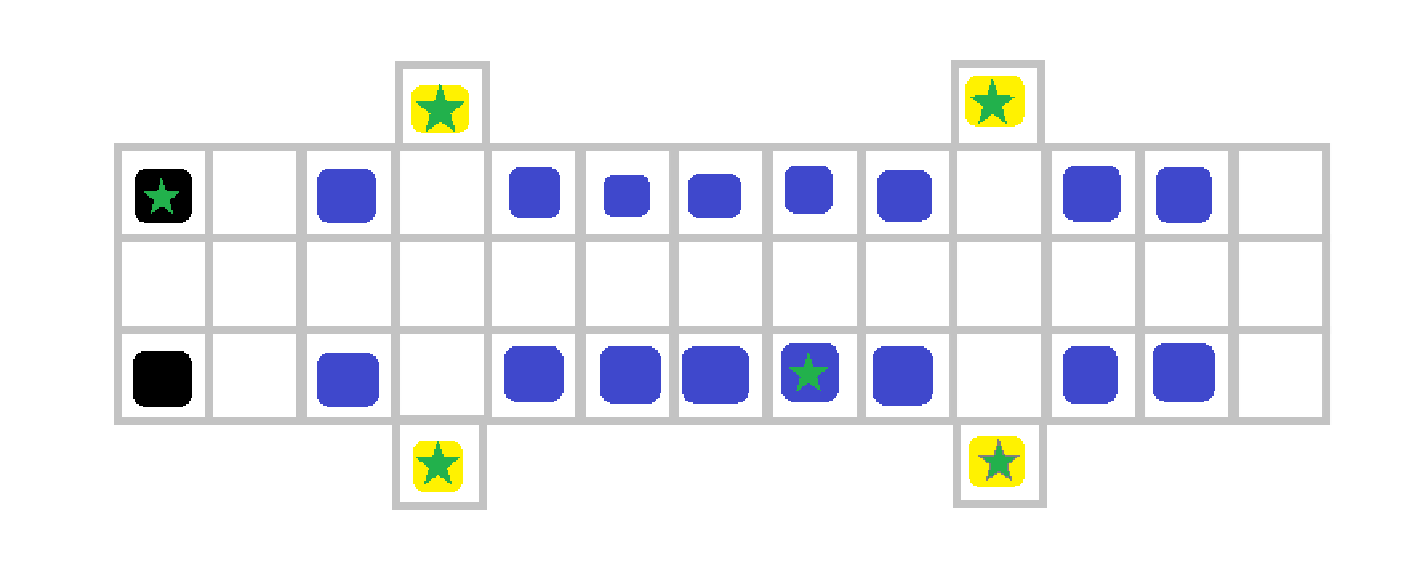

In [15]:
Image(filename='map.png', width=500, height=500)

1. Quadrado azul: assentos do aviao;  
2. Quadrado preto: assentos dos pilotos;  
3. Quadrado amarelo: saida;  
4. Botao amarelo: botao de emergencia interagivel;  

### Regras de movimento e interacao

1. Enquanto estiver preso pelo cinto, o agente quase nao consegue se mover: uma tentativa tem apenas 0,1% de chance de funcionar e recebe penalidade. `largar` solta o cinto, concede recompensa e a mudanca e permanente.
2. O aviao tem nove fileiras na configuracao 2-3-2, com corredores nas colunas 2 e 6.
3. O curriculo comeca com assento e malas fixos; depois varia as malas e, por fim, tambem o assento inicial. A partir da segunda fase, 40% dos episodios comecam com o cinto solto e a saida liberada para praticar a rota final.
4. A chance de atravessar um assento ocupado e constante em 20%; ela nao diminui conforme o agente cruza outros assentos.
5. Duas malas (`M`) aparecem nos corredores. Cada mala pode ser atravessada com 65% de chance por tentativa.
6. O limite de passos diminui progressivamente durante o treinamento; a avaliacao usa um limite mais curto.
7. O agente deve apertar o botao na cabine dos pilotos depois de soltar o cinto. Isso libera a saida, sem carregar um objeto.
8. A saida traseira nao pode ser alcancada nem aberta antes do botao ser apertado.

As coordenadas sao `(x, y)`, com `x` atravessando a cabine e `y` indo da frente para tras. A observacao inclui a posicao do agente, o estado do cinto, se a saida foi liberada, as duas malas e os passos restantes.

Durante o treinamento, a janela mostra episodios reais da exploracao. `TRAINING_ANIMATION_INTERVAL` controla o intervalo; o padrao anima episodios mais avancados para facilitar a visualizacao do aprendizado. Os indicadores na janela mostram, nos 100 episodios anteriores, a frequencia de retirada do cinto, acionamento do botao e chegada a saida.


In [16]:
#montando o ambiente visual em pygame

from numpy import info


class CabinEnv(gym.Env):
    metadata = {"render_modes": ["ansi", "human"], "render_fps": 8}

    ACTIONS = ("cima", "baixo", "esquerda", "direita", "apertar", "largar", "abrir")
    PILOT_POS = (4, 0)
    BUTTON_POS = (3, 0)
    EXIT_POSITIONS = {(4, 10)}
    REAR_EXITS = EXIT_POSITIONS
    SEAT_COLUMNS = (0, 1, 3, 4, 5, 7, 8)
    START_POSITIONS = tuple(
        (x, y)
        for y in range(1, 10)
        for x in (0, 1, 3, 4, 5, 7, 8)
    )
    BAG_CROSSING_PROBABILITY = 0.65
    BAG_ATTEMPT_PENALTY = 0.25
    OBSTACLE_CROSSING_PROBABILITY = 0.2
    OBSTACLE_ATTEMPT_PENALTY = 0.25
    NAVIGATION_SHAPING_SCALE = 0.5
    NAVIGATION_DISCOUNT = 0.99
    BELTED_ESCAPE_PROBABILITY = 0.001
    BELT_RELEASE_REWARD = 5.0
    BUTTON_PRESS_REWARD = 10.0
    BELT_ATTEMPT_PENALTY = 1.0
    BAG_ROWS = tuple(range(1, 10))
    MOVE_DELTAS = {
        0: (0, -1),
        1: (0, 1),
        2: (-1, 0),
        3: (1, 0),
    }

    def __init__(self, max_steps: int = 100, render_mode: str | None = None):
        super().__init__()
        if render_mode not in (None, "ansi", "human"):
            raise ValueError(f"render_mode invalido: {render_mode!r}")

        self.render_mode = render_mode
        self._pygame_screen = None
        self._pygame_font = None
        self._pygame_small_font = None
        self._window_closed = False
        self.training_episode: int | None = None
        self.training_epsilon = 0.0
        self.training_stage_rates = (0.0, 0.0, 0.0)
        self.max_steps = max_steps

        # Nove fileiras de assentos entre o cockpit e a unica saida traseira.
        self.height, self.width = 11, 9
        self.world_map = np.zeros((self.height, self.width), dtype=np.int8)

        # Fileiras de passageiros e corredores laterais.
        self.world_map[1:10, :] = 1
        # Na frente so existe o cockpit e o ponto do botao; atras, so a saida.
        self.world_map[0, self.BUTTON_POS[0]] = 1
        self.world_map[0, self.PILOT_POS[0]] = 1
        for x, y in self.EXIT_POSITIONS:
            self.world_map[y, x] = 1

        # Configuracao transversal 2-3-2; colunas 2 e 6 sao corredores.
        self.obstacles = {
            (x, y)
            for y in range(1, self.height - 1)
            for x in self.SEAT_COLUMNS
        }
        self.obstacle_crossings = len(self.obstacles)
        self._distance_maps: dict[tuple[object, ...], dict[tuple[int, int], float]] = {}
        self.action_space = spaces.Discrete(len(self.ACTIONS))
        self.observation_space = spaces.Box(
            low=np.array([0, 0, 0, 0, 0, 1, 0, 1, 0], dtype=np.int32),
            high=np.array([
                self.width - 1,
                self.height - 1,
                1,
                1,
                self.width - 1,
                self.height - 2,
                self.width - 1,
                self.height - 2,
                self.max_steps,
            ], dtype=np.int32),
            dtype=np.int32,
        )
        self.reset()

    def _get_obs(self) -> np.ndarray:
        (bag1_x, bag1_y), (bag2_x, bag2_y) = sorted(self.bag_positions)
        return np.array([
            self.agent_pos[0],
            self.agent_pos[1],
            int(not self.belt_fastened),
            int(self.exit_unlocked),
            bag1_x,
            bag1_y,
            bag2_x,
            bag2_y,
            self.episode_max_steps - self.steps,
        ], dtype=np.int32)

    def available_actions(self) -> tuple[int, ...]:
        if self.belt_fastened:
            return (5,)

        position = tuple(int(value) for value in self.agent_pos)
        actions = []
        for action, (dx, dy) in self.MOVE_DELTAS.items():
            target = (position[0] + dx, position[1] + dy)
            if self._is_walkable(target) and not (
                target in self.EXIT_POSITIONS and not self.exit_unlocked
            ):
                actions.append(action)
        if position == self.BUTTON_POS and not self.exit_unlocked:
            actions.append(4)
        if position in self.EXIT_POSITIONS and self.exit_unlocked:
            actions.append(6)
        return tuple(actions)

    def _is_walkable(self, position: tuple[int, int]) -> bool:
        x, y = position
        return (
            0 <= x < self.width
            and 0 <= y < self.height
            and self.world_map[y, x] == 1
        )

    def _navigation_distance(self) -> float | None:
        if self.exit_unlocked:
            targets = self.EXIT_POSITIONS
        elif not self.belt_fastened:
            targets = {self.BUTTON_POS}
        else:
            return None

        start = tuple(int(value) for value in self.agent_pos)
        cache_key = (tuple(sorted(self.bag_positions)), tuple(sorted(targets)))

        if cache_key not in self._distance_maps:
            distances = {target: 0.0 for target in targets}
            frontier = [(0.0, target) for target in targets]
            heapq.heapify(frontier)

            while frontier:
                distance, position = heapq.heappop(frontier)
                if distance != distances.get(position):
                    continue

                if position in self.bag_positions:
                    tile_cost = 1.0 / self.BAG_CROSSING_PROBABILITY
                elif position in self.obstacles:
                    tile_cost = 1.0 / self.OBSTACLE_CROSSING_PROBABILITY
                else:
                    tile_cost = 1.0

                x, y = position
                for dx, dy in self.MOVE_DELTAS.values():
                    previous = (x + dx, y + dy)
                    if not self._is_walkable(previous):
                        continue
                    candidate = distance + tile_cost
                    if candidate < distances.get(previous, float("inf")):
                        distances[previous] = candidate
                        heapq.heappush(frontier, (candidate, previous))

                if position == start:
                    break

            self._distance_maps[cache_key] = distances

        return self._distance_maps[cache_key].get(start, float("inf"))

    def reset(
        self,
        *,
        seed: int | None = None,
        options: dict[str, object] | None = None,
    ) -> tuple[np.ndarray, dict[str, object]]:
        super().reset(seed=seed)
        options = options or {}

        start_pos = options.get("start_pos")
        if start_pos is None:
            start_pos = self.START_POSITIONS[int(self.np_random.integers(len(self.START_POSITIONS)))]
        start_pos = tuple(int(value) for value in start_pos)
        walkable_start_positions = tuple(
            (x, y)
            for y in range(1, self.height - 1)
            for x in range(self.width)
            if self._is_walkable((x, y))
        )
        allowed_start_positions = walkable_start_positions + (self.BUTTON_POS,)
        if start_pos not in allowed_start_positions:
            raise ValueError(f"Posicao inicial invalida: {start_pos!r}")
        if start_pos == self.BUTTON_POS and not bool(options.get("exit_unlocked", False)):
            raise ValueError("O inicio no botao exige exit_unlocked=True.")

        bag_positions = options.get("bag_positions")
        if bag_positions is None:
            left_bag_row = int(self.np_random.choice(self.BAG_ROWS))
            right_bag_row = int(self.np_random.choice(self.BAG_ROWS))
            bag_positions = ((2, left_bag_row), (6, right_bag_row))
        bag_positions = tuple(tuple(int(value) for value in pos) for pos in bag_positions)
        if (
            len(bag_positions) != 2
            or bag_positions[0][0] != 2
            or bag_positions[1][0] != 6
            or bag_positions[0][1] not in self.BAG_ROWS
            or bag_positions[1][1] not in self.BAG_ROWS
        ):
            raise ValueError("Use uma mala em cada corredor, entre as fileiras 1 e 9.")

        episode_max_steps = int(options.get("episode_max_steps", self.max_steps))
        if not 1 <= episode_max_steps <= self.max_steps:
            raise ValueError(
                f"episode_max_steps deve estar entre 1 e {self.max_steps}."
            )

        belt_fastened = options.get("belt_fastened", True)
        exit_unlocked = options.get("exit_unlocked", False)
        if not isinstance(belt_fastened, bool) or not isinstance(exit_unlocked, bool):
            raise ValueError("belt_fastened e exit_unlocked devem ser valores booleanos.")
        if exit_unlocked and belt_fastened:
            raise ValueError("A saida liberada exige que o cinto esteja solto.")

        self.agent_pos = np.array(start_pos, dtype=np.int32)
        self.episode_max_steps = episode_max_steps
        self.bag_positions = set(bag_positions)
        self.belt_fastened = belt_fastened
        self.exit_unlocked = exit_unlocked
        self.button_position: tuple[int, int] | None = self.BUTTON_POS
        self.obstacles_crossed = 0
        self.steps = 0
        return self._get_obs(), {
            "start_pos": start_pos,
            "bag_positions": tuple(sorted(self.bag_positions)),
            "episode_max_steps": self.episode_max_steps,
        }

    def step(
        self, action: int
    ) -> tuple[np.ndarray, float, bool, bool, dict[str, object]]:
        if not self.action_space.contains(action):
            raise ValueError(f"Acao fora do espaco valido: {action!r}")

        self.steps += 1
        reward = -0.05
        terminated = False
        info: dict[str, object] = {}
        old_distance = self._navigation_distance()

        if action in self.MOVE_DELTAS:
            dx, dy = self.MOVE_DELTAS[action]
            next_pos = (int(self.agent_pos[0]) + dx, int(self.agent_pos[1]) + dy)
            if not self._is_walkable(next_pos):
                reward -= 1.0
                info["invalid_move"] = True
            elif next_pos in self.EXIT_POSITIONS and not self.exit_unlocked:
                reward -= 1.5
                info["exit_locked"] = True
            elif self.belt_fastened:
                probability = self.BELTED_ESCAPE_PROBABILITY
                info["belted_escape_probability"] = probability
                reward -= self.BELT_ATTEMPT_PENALTY
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    info["moved_while_belted"] = True
                else:
                    info["moved_while_belted"] = False
            elif next_pos in self.bag_positions:
                probability = self.BAG_CROSSING_PROBABILITY
                info["bag_crossing_probability"] = probability
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    reward -= 0.5
                    info["bag_crossed"] = True
                else:
                    reward -= self.BAG_ATTEMPT_PENALTY
                    info["bag_crossed"] = False
            elif next_pos in self.obstacles:
                probability = self.OBSTACLE_CROSSING_PROBABILITY
                info["obstacle_crossing_probability"] = probability
                if self.np_random.random() < probability:
                    self.agent_pos[:] = next_pos
                    self.obstacles_crossed = min(
                        self.obstacles_crossed + 1, self.obstacle_crossings
                    )
                    reward -= 0.25
                    info["obstacle_crossed"] = True
                else:
                    reward -= self.OBSTACLE_ATTEMPT_PENALTY
                    info["obstacle_crossed"] = False
            else:
                self.agent_pos[:] = next_pos

            if tuple(int(value) for value in self.agent_pos) in self.EXIT_POSITIONS:
                info["exit_reached"] = True
            new_distance = self._navigation_distance()
            if (
                old_distance is not None
                and new_distance is not None
                and np.isfinite(old_distance)
                and np.isfinite(new_distance)
            ):
                reward += self.NAVIGATION_SHAPING_SCALE * (self.NAVIGATION_DISCOUNT * (-new_distance) - (-old_distance))

        elif action == 4:
            current_pos = tuple(int(value) for value in self.agent_pos)
            if self.belt_fastened:
                reward -= 1.5
            elif self.exit_unlocked:
                reward -= 1.0
                info["button_already_pressed"] = True
            elif current_pos == self.BUTTON_POS:
                self.exit_unlocked = True
                reward += self.BUTTON_PRESS_REWARD
                info["button_pressed"] = True
            else:
                reward -= 1.0

        elif action == 5:
            if self.belt_fastened:
                self.belt_fastened = False
                reward += self.BELT_RELEASE_REWARD
                info["belt_released"] = True
            else:
                reward -= 1.0
                info["belt_already_released"] = True

        elif action == 6:
            current_pos = tuple(int(value) for value in self.agent_pos)
            if (
                not self.belt_fastened
                and self.exit_unlocked
                and current_pos in self.EXIT_POSITIONS
            ):
                terminated = True
                reward += 100.0
                if current_pos in self.REAR_EXITS:
                    reward += 15.0
                info["success"] = True
                info["exit"] = "traseira" if current_pos in self.REAR_EXITS else "frontal"
            else:
                reward -= 1.5

        truncated = self.steps >= self.episode_max_steps and not terminated
        return self._get_obs(), reward, terminated, truncated, info

    def render(self) -> str | None:
        if self.render_mode is None:
            return None

        if self.render_mode == "ansi":
            grid = [
                ["." if self.world_map[y, x] else " " for x in range(self.width)]
                for y in range(self.height)
            ]
            for x, y in self.obstacles:
                grid[y][x] = "#"

            for x, y in self.EXIT_POSITIONS:
                grid[y][x] = "E"

            for x, y in self.bag_positions:
                grid[y][x] = "M"

            grid[self.PILOT_POS[1]][self.PILOT_POS[0]] = "P"

            if self.button_position is not None:
                bx, by = self.button_position
                grid[by][bx] = "b" if self.exit_unlocked else "B"

            x, y = (int(value) for value in self.agent_pos)
            grid[y][x] = "A"
            rows = [" ".join(row) for row in grid]

            rows.append(
                f"cinto={'preso' if self.belt_fastened else 'solto'} | "
                f"botao={'apertado' if self.exit_unlocked else 'pendente'} | "
                f"obstaculos={self.obstacles_crossed}/{self.obstacle_crossings} | "
                f"passos={self.steps}/{self.episode_max_steps}"
            )

            rows.append(
                f"Legenda: A agente, P cockpit, B botao, b apertado, # assento, "
                f"M mala ({self.BAG_CROSSING_PROBABILITY:.0%}), E saida"
            )

            rows.append("Assentos por fileira: ## . ### . ## (pontos sao corredores)")
            return "\n".join(rows)

        if self._window_closed:
            return None

        cell_size = 58
        margin = 44
        top = 104
        window_width = margin * 2 + self.width * cell_size
        window_height = top + self.height * cell_size + 44

        if self._pygame_screen is None:
            pygame.init()
            self._pygame_screen = pygame.display.set_mode((window_width, window_height))
            pygame.display.set_caption("CabinEnv - episodio do agente")
            self._pygame_font = pygame.font.Font(None, 28)
            self._pygame_small_font = pygame.font.Font(None, 21)

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self._window_closed = True
                self.close()
                return None

        screen = self._pygame_screen
        screen.fill((238, 242, 247))
        title_text = (
            f"Treino | episodio {self.training_episode} | "
            f"epsilon {self.training_epsilon:.2f}"
            if self.training_episode is not None
            else "Escape do aviao"
        )

        title = self._pygame_font.render(title_text, True, (28, 42, 58))
        screen.blit(title, (margin, 24))
        status = (
            f"Passo {self.steps}/{self.episode_max_steps}   "
            f"Cinto: {'preso' if self.belt_fastened else 'solto'}   "
            f"Botao: {'apertado' if self.exit_unlocked else 'pendente'}"
        )

        screen.blit(self._pygame_small_font.render(status, True, (48, 61, 76)), (margin, 62))
        belt_rate, button_rate, exit_rate = self.training_stage_rates
        progress = (
            f"Ultimos 100 episodios: cinto {belt_rate:.0%} | "
            f"botao {button_rate:.0%} | saida {exit_rate:.0%}"
        )

        screen.blit(self._pygame_small_font.render(progress, True, (48, 61, 76)), (margin, 82))

        aisle_color = (218, 226, 232)
        seat_color = (54, 91, 174)
        for y in range(self.height):
            for x in range(self.width):
                rect = pygame.Rect(
                    margin + x * cell_size + 3,
                    top + y * cell_size + 3,
                    cell_size - 6,
                    cell_size - 6,
                )

                position = (x, y)
                color = aisle_color if x in (2, 6) else (248, 249, 250)
                pygame.draw.rect(screen, color, rect, border_radius=8)

                if position in self.obstacles:
                    pygame.draw.rect(screen, seat_color, rect.inflate(-10, -8), border_radius=10)

                if position == self.PILOT_POS:
                    pygame.draw.rect(screen, (42, 48, 58), rect.inflate(-8, -8), border_radius=8)
                    label = self._pygame_small_font.render("P", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))

                if position in self.EXIT_POSITIONS:
                    pygame.draw.rect(screen, (42, 157, 105), rect.inflate(-8, -8), border_radius=8)
                    label = self._pygame_small_font.render("SAIDA", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))

                if position in self.bag_positions:
                    pygame.draw.rect(screen, (173, 105, 45), rect.inflate(-12, -14), border_radius=7)
                    label = self._pygame_font.render("M", True, (255, 255, 255))
                    screen.blit(label, label.get_rect(center=rect.center))

                if position == self.button_position:
                    pygame.draw.circle(screen, (237, 190, 48), rect.center, 18)
                    label = self._pygame_small_font.render("b" if self.exit_unlocked else "B", True, (45, 50, 55))
                    screen.blit(label, label.get_rect(center=rect.center))

        agent_x, agent_y = (int(value) for value in self.agent_pos)

        agent_center = (
            margin + agent_x * cell_size + cell_size // 2,
            top + agent_y * cell_size + cell_size // 2,
        )

        pygame.draw.circle(screen, (215, 54, 75), agent_center, 18)
        pygame.draw.circle(screen, (255, 255, 255), agent_center, 18, width=3)
        pygame.display.flip()

        return None

    @property
    def window_closed(self) -> bool:
        return self._window_closed

    def close(self) -> None:
        if self._pygame_screen is not None:
            pygame.display.quit()
            self._pygame_screen = None
            self._pygame_font = None
            self._pygame_small_font = None


Formato da observacao: (9,)
Acoes (0-6): ('cima', 'baixo', 'esquerda', 'direita', 'apertar', 'largar', 'abrir')
Estados visitados: 95793
Sucesso na avaliacao: 756/1000 (75.6%)
IC 95% Wilson: [72.8%, 78.2%]
Retorno medio na avaliacao: 112.35
Passos medios/medianos nos sucessos: 61.2/60.5
Passos em estados nao vistos: 3148/68226 (4.6%)
Sucesso apos liberar o botao: 756/970 (77.9%)
Botao liberado: 970/1000 (97.0%)
Chegou a saida: 760/1000 (76.0%)
Escapou: 756/1000 (75.6%)
Timeout antes_botao: 30/1000 (3.0%)
Timeout antes_saida: 214/1000 (21.4%)
Sucesso por fileira inicial: {1: '84.8%', 2: '81.5%', 3: '85.4%', 4: '68.7%', 5: '76.9%', 6: '74.5%', 7: '70.6%', 8: '67.9%', 9: '71.1%'}
Teto teorico estimado (200 cenarios): 99.9%


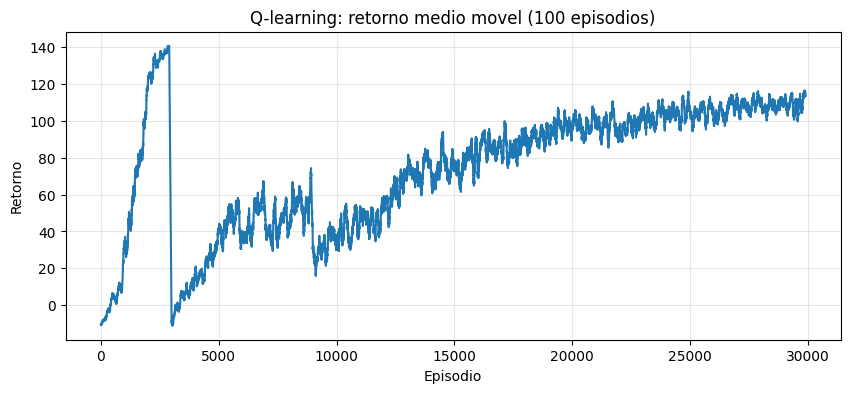

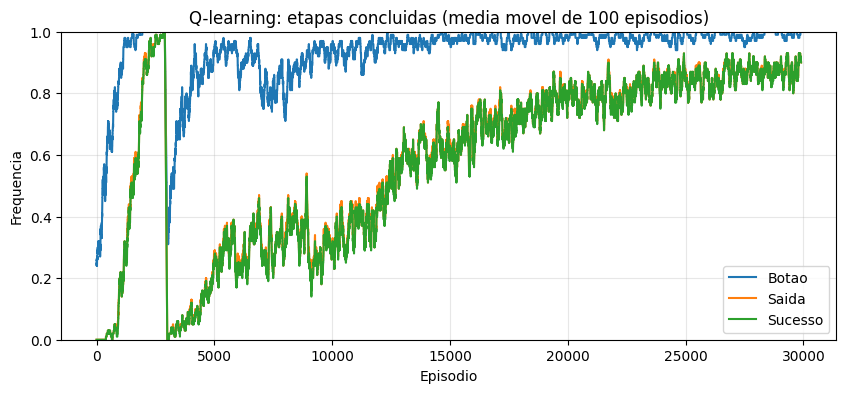

In [17]:
# Registra o ambiente para que o checker consiga testar os render_modes.
CABIN_ENV_ID = "CabinEnv-v0"
if CABIN_ENV_ID not in gym.registry:
    gym.register(id=CABIN_ENV_ID, entry_point=CabinEnv)

validation_env = gym.make(CABIN_ENV_ID)
try:
    check_env(validation_env.unwrapped, skip_render_check=True)
finally:
    validation_env.close()

ANIMATE_TRAINING = True
TRAINING_ANIMATION_INTERVAL = 2000
ANIMATION_DELAY = 0.02
if TRAINING_ANIMATION_INTERVAL < 1:
    raise ValueError("TRAINING_ANIMATION_INTERVAL deve ser pelo menos 1.")

env = CabinEnv(render_mode="human" if ANIMATE_TRAINING else "ansi")
obs, info = env.reset(seed=42)
print("Formato da observacao:", obs.shape)
print("Acoes (0-6):", CabinEnv.ACTIONS)

# O Q-learning usa fase e linhas relativas das malas, reduzindo estados redundantes.
q_table: dict[tuple[int, ...], np.ndarray] = {}
q_table_b: dict[tuple[int, ...], np.ndarray] = {}
visit_counts: dict[tuple[int, ...], np.ndarray] = {}

rng = np.random.default_rng(42)
env.action_space.seed(42)

discount = 0.99
num_episodes = 30000

EVALUATION_MAX_STEPS = 90
FIXED_START_POS = (4, 5)
FIXED_BAG_POSITIONS = ((2, 4), (6, 6))
CURRICULUM_FIXED_EPISODES = 3000
CURRICULUM_INTERMEDIATE_EPISODES = 9000
CURRICULUM_RANDOM_BAGS_EPISODE = 7000
EXIT_STAGE_TRAINING_FRACTION = 0.75


def training_deadline(episode: int) -> int:
    if episode < 3000:
        return 100
    if episode < 6000:
        return 90
    if episode < 9000:
        return 80
    if episode < 12000:
        return 70
    return EVALUATION_MAX_STEPS

def get_state_key(state: np.ndarray) -> tuple[int, ...]:
    values = tuple(int(value) for value in state)
    x, y = values[0], values[1]
    phase = 0 if not values[2] else (2 if values[3] else 1)
    bag_rows_relative = (values[5] - y, values[7] - y)
    remaining = values[-1]
    remaining_bucket = remaining if remaining <= 10 else ((remaining + 9) // 10) * 10

    return (x, y, phase, *bag_rows_relative, remaining_bucket)


def get_q_values(state: np.ndarray) -> np.ndarray:
    key = get_state_key(state)
    values_a = q_table.setdefault(key, np.zeros(env.action_space.n, dtype=np.float64))
    values_b = q_table_b.setdefault(key, np.zeros(env.action_space.n, dtype=np.float64))

    return values_a + values_b


def guided_action(environment: CabinEnv, actions: tuple[int, ...]) -> int:
    if 5 in actions and environment.belt_fastened:
        return 5

    position = tuple(int(value) for value in environment.agent_pos)
    if 4 in actions and position == environment.BUTTON_POS:
        return 4

    if 6 in actions and position in environment.EXIT_POSITIONS:
        return 6

    candidates = []
    original_position = environment.agent_pos.copy()

    for action in actions:
        if action not in environment.MOVE_DELTAS:
            continue

        dx, dy = environment.MOVE_DELTAS[action]
        candidate = (position[0] + dx, position[1] + dy)

        if not environment._is_walkable(candidate):
            continue

        environment.agent_pos[:] = candidate
        distance = environment._navigation_distance()
        environment.agent_pos[:] = original_position
        candidates.append((float("inf") if distance is None else distance, action))

    return min(candidates)[1] if candidates else int(actions[0])


training_returns = []
training_progress: list[tuple[bool, bool, bool, bool]] = []

for episode in range(num_episodes):
    deadline = training_deadline(episode)
    reset_options: dict[str, object] = {"episode_max_steps": deadline}

    if episode < CURRICULUM_FIXED_EPISODES:
        reset_options.update({"start_pos": FIXED_START_POS, "bag_positions": FIXED_BAG_POSITIONS})

    elif episode < CURRICULUM_INTERMEDIATE_EPISODES:
        reset_options.update({"belt_fastened": False, "exit_unlocked": False})

        if episode < CURRICULUM_RANDOM_BAGS_EPISODE:
            reset_options["start_pos"] = FIXED_START_POS

    else:
        train_exit_stage = rng.random() < EXIT_STAGE_TRAINING_FRACTION

        if train_exit_stage:

            exit_starts = (
                CabinEnv.BUTTON_POS,
                (2, 1), (2, 2), (2, 4), (2, 6), (2, 8),
                (6, 1), (6, 2), (6, 4), (6, 6), (6, 8),
            )

            reset_options.update({
                "start_pos": exit_starts[int(rng.integers(len(exit_starts)))],
                "belt_fastened": False,
                "exit_unlocked": True,
                "episode_max_steps": max(25, deadline - 25),
            })

    state, _ = env.reset(seed=episode + 100, options=reset_options)

    if episode < CURRICULUM_FIXED_EPISODES:
        epsilon = max(0.08, 1.0 - 0.92 * episode / CURRICULUM_FIXED_EPISODES)

    elif episode < CURRICULUM_INTERMEDIATE_EPISODES:
        epsilon = max(0.10, 0.30 - 0.22 * (episode - CURRICULUM_FIXED_EPISODES) / 6000)

    else:
        epsilon = max(0.05, 0.30 - 0.27 * (episode - CURRICULUM_INTERMEDIATE_EPISODES) / 21000)

    episode_return = 0.0
    episode_belt_released = not env.belt_fastened
    episode_button_pressed = env.exit_unlocked
    episode_exit_reached = False

    animate_this_episode = (
        ANIMATE_TRAINING and episode > 0
        and episode % TRAINING_ANIMATION_INTERVAL == 0
        and not env.window_closed
    )

    if animate_this_episode:
        recent = training_progress[-100:]

        if recent:
            env.training_stage_rates = tuple(sum(row[index] for row in recent) / len(recent) for index in range(3))
        env.training_episode = episode + 1
        env.training_epsilon = epsilon
        env.render()

    for _ in range(env.max_steps):
        key = get_state_key(state)
        q_values = get_q_values(state)
        available_actions = env.available_actions()

        if rng.random() < epsilon:
            if rng.random() < 0.08:
                action = guided_action(env, available_actions)
            else:
                action = int(rng.choice(available_actions))

        else:
            action_indices = np.array(available_actions, dtype=int)
            action = int(action_indices[np.argmax(q_values[action_indices] + rng.random(len(action_indices)) * 1e-8)])

        next_state, reward, terminated, truncated, step_info = env.step(action)
        episode_belt_released |= bool(step_info.get("belt_released", False))
        episode_button_pressed |= bool(step_info.get("button_pressed", False))
        episode_exit_reached |= bool(step_info.get("exit_reached", False))

        if step_info.get("obstacle_crossed") is False:
            reward -= 0.10

        if not np.isfinite(reward):
            raise FloatingPointError(f"Reward invalido: {reward}")

        next_key = get_state_key(next_state)
        next_q_values = get_q_values(next_state)
        done = terminated or truncated
        target = reward

        if not done:
            next_actions = np.array(env.available_actions(), dtype=int)
            if len(next_actions):
                target += discount * float(np.max(next_q_values[next_actions]))
        counts = visit_counts.setdefault(key, np.zeros(env.action_space.n, dtype=np.int64))
        counts[action] += 1
        alpha = max(0.02, 1.0 / counts[action] ** 0.6)

        if rng.random() < 0.5:
            values = q_table[key]
            other_values = q_table_b.setdefault(next_key, np.zeros(env.action_space.n, dtype=np.float64))
            if not done and len(next_actions):
                best_next = int(next_actions[np.argmax(q_table[next_key][next_actions])])
                target = reward + discount * float(other_values[best_next])
            if not np.isfinite(target):
                raise FloatingPointError(f"Target invalido: {target}")
            values[action] += alpha * (target - values[action])

        else:
            values = q_table_b[key]
            other_values = q_table.setdefault(next_key, np.zeros(env.action_space.n, dtype=np.float64))
            if not done and len(next_actions):
                best_next = int(next_actions[np.argmax(q_table_b[next_key][next_actions])])
                target = reward + discount * float(other_values[best_next])
            if not np.isfinite(target):
                raise FloatingPointError(f"Target invalido: {target}")
            values[action] += alpha * (target - values[action])

        state = next_state
        episode_return += reward

        if animate_this_episode and not env.window_closed:
            env.render()
            time.sleep(ANIMATION_DELAY)

        if terminated or truncated:
            break

    training_returns.append(episode_return)
    training_progress.append((episode_belt_released, episode_button_pressed, episode_exit_reached, terminated))

env.close()

# Avaliacao corrigida: cada episodio recebe uma seed globalmente distinta da de treino.
EVALUATION_SEEDS = tuple(range(10))
EVALUATION_EPISODES_PER_SEED = 100

evaluation_records: list[dict[str, object]] = []
evaluation_unseen_steps = 0
evaluation_total_steps = 0

for evaluation_seed in EVALUATION_SEEDS:
    for episode in range(EVALUATION_EPISODES_PER_SEED):
        unique_seed = 1_000_000 + evaluation_seed * 1000 + episode
        state, reset_info = env.reset(seed=unique_seed, options={"episode_max_steps": EVALUATION_MAX_STEPS})
        episode_return = 0.0
        episode_milestones = [False, False, False]
        steps_taken = 0
        terminated = False
        unseen_steps = 0

        for steps_taken in range(1, env.max_steps + 1):
            key = get_state_key(state)
            action_values = q_table.get(key, np.zeros(env.action_space.n)) + q_table_b.get(key, np.zeros(env.action_space.n))
            action_indices = np.array(env.available_actions(), dtype=int)

            if key not in q_table or key not in q_table_b:
                unseen_steps += 1
                action = guided_action(env, tuple(int(value) for value in action_indices))

            else:
                action = int(action_indices[np.argmax(action_values[action_indices])])

            evaluation_total_steps += 1
            evaluation_unseen_steps += int(key not in q_table or key not in q_table_b)
            state, reward, terminated, truncated, step_info = env.step(action)
            episode_return += reward
            episode_milestones[0] |= bool(step_info.get("belt_released", False))
            episode_milestones[1] |= bool(step_info.get("button_pressed", False))
            episode_milestones[2] |= bool(step_info.get("exit_reached", False))

            if terminated or truncated:
                break
        timeout_phase = None

        if truncated:
            timeout_phase = "antes_botao" if not episode_milestones[1] else "antes_saida"

        evaluation_records.append({
            "seed": evaluation_seed,
            "start_pos": reset_info["start_pos"],
            "bag_positions": reset_info["bag_positions"],
            "return": episode_return,
            "steps": steps_taken,
            "progress": (*episode_milestones, terminated),
            "unseen_steps": unseen_steps,
            "timeout_phase": timeout_phase,
        })

evaluation_progress = [record["progress"] for record in evaluation_records]
evaluation_returns = [record["return"] for record in evaluation_records]
button_records = [record for record in evaluation_records if record["progress"][1]]
exit_after_button = sum(record["progress"][3] for record in button_records)
evaluation_successes = sum(row[3] for row in evaluation_progress)
mean_steps_success = np.mean([record["steps"] for record in evaluation_records if record["progress"][3]])
median_steps_success = np.median([record["steps"] for record in evaluation_records if record["progress"][3]])

def wilson_interval(successes: int, total: int, z: float = 1.96) -> tuple[float, float]:
    if total == 0:
        return (float("nan"), float("nan"))
    p = successes / total
    denominator = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denominator
    margin = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return centre - margin, centre + margin

success_ci = wilson_interval(evaluation_successes, len(evaluation_records))

print(f"Estados visitados: {len(q_table)}")
print(f"Sucesso na avaliacao: {evaluation_successes}/{len(evaluation_records)} ({evaluation_successes / len(evaluation_records):.1%})")
print(f"IC 95% Wilson: [{success_ci[0]:.1%}, {success_ci[1]:.1%}]")
print(f"Retorno medio na avaliacao: {np.mean(evaluation_returns):.2f}")
print(f"Passos medios/medianos nos sucessos: {mean_steps_success:.1f}/{median_steps_success:.1f}")
print(f"Passos em estados nao vistos: {evaluation_unseen_steps}/{evaluation_total_steps} ({evaluation_unseen_steps / evaluation_total_steps:.1%})")
print(f"Sucesso apos liberar o botao: {exit_after_button}/{len(button_records)} ({exit_after_button / len(button_records):.1%})")

for index, label in enumerate(("Botao liberado", "Chegou a saida", "Escapou"), start=1):
    count = sum(row[index] for row in evaluation_progress)
    print(f"{label}: {count}/{len(evaluation_records)} ({count / len(evaluation_records):.1%})")

for phase in ("antes_botao", "antes_saida"):
    count = sum(record["timeout_phase"] == phase for record in evaluation_records)
    print(f"Timeout {phase}: {count}/{len(evaluation_records)} ({count / len(evaluation_records):.1%})")

row_rates = {}

for row in sorted({record["start_pos"][1] for record in evaluation_records}):
    records = [record for record in evaluation_records if record["start_pos"][1] == row]
    row_rates[row] = np.mean([record["progress"][3] for record in records])

print("Sucesso por fileira inicial:", {row: f"{rate:.1%}" for row, rate in row_rates.items()})

# Teto teorico por programacao dinamica do MDP (amostra dos cenarios avaliados).
def theoretical_success_ceiling(records: list[dict[str, object]]) -> float:
    from functools import lru_cache
    obstacle_positions = frozenset((x, y) for y in range(1, env.height - 1) for x in env.SEAT_COLUMNS)
    walkable = frozenset((x, y) for y in range(env.height) for x in range(env.width) if env.world_map[y, x] == 1)
    deltas = tuple(env.MOVE_DELTAS.values())

    @lru_cache(maxsize=None)
    def value(x: int, y: int, phase: int, left_row: int, right_row: int, steps_left: int) -> float:
        if steps_left <= 0:
            return 0.0
        bags = {(2, left_row), (6, right_row)}
        actions = []

        if phase == 0:
            actions.append(("release", None))

        else:
            for action, (dx, dy) in env.MOVE_DELTAS.items():
                target = (x + dx, y + dy)
                if target in walkable and not (target in env.EXIT_POSITIONS and phase < 2):
                    actions.append(("move", target))
            if phase == 1 and (x, y) == env.BUTTON_POS:
                actions.append(("button", None))
            if phase == 2 and (x, y) in env.EXIT_POSITIONS:
                actions.append(("open", None))

        best = 0.0

        for kind, target in actions:
            if kind == "release":
                candidate = value(x, y, 1, left_row, right_row, steps_left - 1)
            elif kind == "button":
                candidate = value(x, y, 2, left_row, right_row, steps_left - 1)
            elif kind == "open":
                candidate = 1.0
            else:
                tx, ty = target
                if target in bags:
                    probability = env.BAG_CROSSING_PROBABILITY
                elif target in obstacle_positions:
                    probability = env.OBSTACLE_CROSSING_PROBABILITY
                else:
                    probability = 1.0
                moved = value(tx, ty, phase, left_row, right_row, steps_left - 1)
                stayed = value(x, y, phase, left_row, right_row, steps_left - 1)
                candidate = probability * moved + (1 - probability) * stayed
            best = max(best, candidate)

        return best

    values = [value(record["start_pos"][0], record["start_pos"][1], 0, record["bag_positions"][0][1], record["bag_positions"][1][1], EVALUATION_MAX_STEPS) for record in records]
    return float(np.mean(values))

VALUE_ITERATION_SCENARIOS = 200
ceiling = theoretical_success_ceiling(evaluation_records[:VALUE_ITERATION_SCENARIOS])
print(f"Teto teorico estimado ({VALUE_ITERATION_SCENARIOS} cenarios): {ceiling:.1%}")

window = 100
moving_average = np.convolve(training_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.title("Q-learning: retorno medio movel (100 episodios)")
plt.xlabel("Episodio")
plt.ylabel("Retorno")
plt.grid(alpha=0.3)

plt.figure(figsize=(10, 4))

for index, label in enumerate(("Botao", "Saida", "Sucesso"), start=1):
    milestone_rate = np.convolve(np.array([row[index] for row in training_progress], dtype=float), np.ones(window) / window, mode="valid")
    plt.plot(milestone_rate, label=label)

plt.title("Q-learning: etapas concluidas (media movel de 100 episodios)")
plt.xlabel("Episodio")
plt.ylabel("Frequencia")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()
